# Lab 6.3 Camera Pose Estimation

In this lab you will use RANSAC camera pose estimation in order to identify a tracking target and place a 3D model on top of it.

In [366]:
!wget -q -nc -O stones.png "https://www.dropbox.com/scl/fi/iztxkmviroy98ym76awjc/stones.png?rlkey=3mppovw9uqdr36hx3al802k8x&dl=1"
!wget -q -nc -O stones1.png "https://www.dropbox.com/scl/fi/ipi956smdi6kk61d337p1/stones1.png?rlkey=ph7uc9g7p9vjebhu1wei6pmf0&dl=1"
!wget -q -nc -O overlay.png "https://www.dropbox.com/scl/fi/277ackgsz1w5fwyftnkqm/overlay.png?rlkey=2q9reczn9ojl6sh54jf4itsjp&dl=1"

In [367]:
import matplotlib.pyplot as plt

import numpy as np
import imageio
import skimage
from skimage.color import rgb2gray
from skimage.feature import match_descriptors, plot_matched_features, SIFT
import cv2

The "reference" image (`ref_img`) is the image I printed out and put on the table.  

The "video" image (`vid_img`) is a frame from the video I took of the table.  

In [368]:
ref_img = imageio.imread('stones.png')[...,:3]
vid_img = imageio.imread('stones1.png')

/var/folders/cn/043rpj9s7gn508l3jykd91gh0000gn/T/ipykernel_94091/3746280271.py:1: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  ref_img = imageio.imread('stones.png')[...,:3]
/var/folders/cn/043rpj9s7gn508l3jykd91gh0000gn/T/ipykernel_94091/3746280271.py:2: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  vid_img = imageio.imread('stones1.png')


Here are the camera intrinsics.

In [369]:
focal = 1.9432969355531013e+03 / 4
cx = 5.3950000000000000e+02 / 4
cy = 9.5950000000000000e+02 / 4

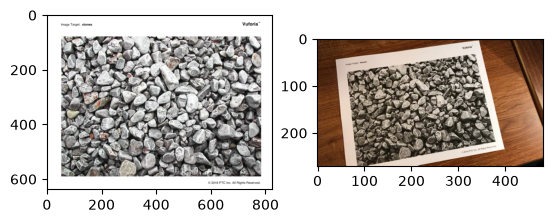

In [370]:
fig,axes = plt.subplots(1,2)
axes[0].imshow(ref_img)
axes[1].imshow(vid_img)


Let's compute and match SIFT descriptors between them.

In [371]:
descriptor_extractor = SIFT()

In [372]:
descriptor_extractor.detect_and_extract(rgb2gray(ref_img))
keypoints1 = descriptor_extractor.keypoints
descriptors1 = descriptor_extractor.descriptors

In [373]:
descriptor_extractor.detect_and_extract(rgb2gray(vid_img))
keypoints2 = descriptor_extractor.keypoints
descriptors2 = descriptor_extractor.descriptors

In [374]:
matches12 = match_descriptors(
    descriptors1, descriptors2, max_ratio=0.7, cross_check=True
)

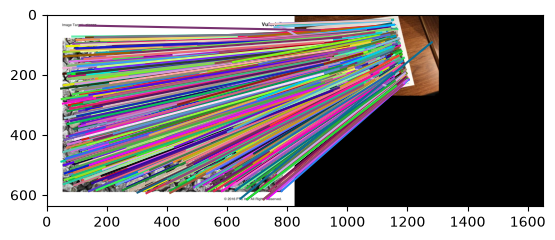

In [375]:
fig,ax = plt.subplots()
plot_matched_features(ref_img, vid_img, keypoints0=keypoints1, keypoints1=keypoints2, matches=matches12, ax=ax, only_matches=True)

# Exercises

1. Now use OpenCV's `solvePnPRansac` function to find the camera pose using RANSAC.

Run `cv2.solvePnPRansac` as follows:


    _, rvec, tvec, inliers = cv2.solvePnPRansac(objectPoints, imagePoints, cameraMatrix, None, flags=cv2.SOLVEPNP_EPNP)
    inliers = inliers[:,0]

You will need to build the `cameraMatrix` using the provided intrinsics.

For the `objectPoints` (the 3D points on the object), use 2D keypoints in `ref_img` for X and Y, and set the Z value to 0 for all points.  This sets a world coordinate system where the origin is the top-left corner of the reference image, and the table is a plane at Z=0.

For the `imagePoints` use the matching 2D keypoints in the `vid_img`.

`rvec` is a 3-vector representing the estimated rotation
`tvec` is a 3-vector for the estimated translation
`inliers` is a list of indices for the inlier matches.

2. Show the inlier matches (using `plot_matched_features`) to check that it has found a good solution.

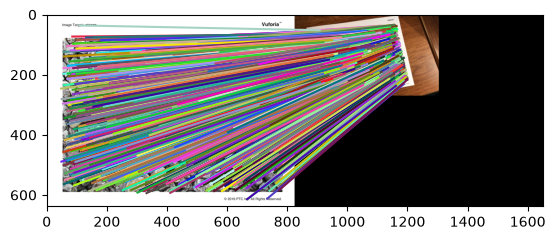

3. Project the corners of the tracking target to the image using the estimated rotation and translation.

To do this, create 3D points at the corners of the reference image.

Project them using `cv2.projectPoints`.

Then show the image and plot the projected points on top.  Verify that they are on the corners of the tracking target (or at least, they are close).

(I'm not sure I have the intrinsics correct for this image, which is why the solution might be slightly off.)



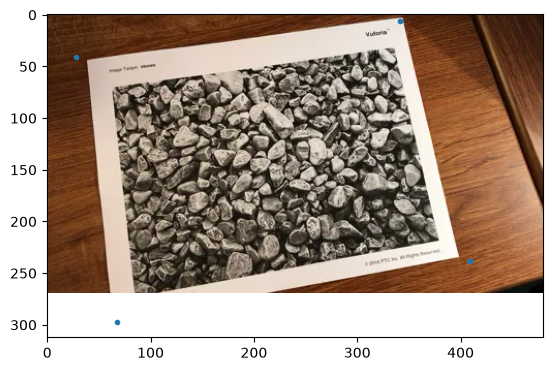

4. Here I provide code to draw a box on the image and play with its position and orientation using sliders.

Enjoy playing with it!

In [380]:
def make_cube(R=200):
    # draw a cube centered at (0,0,0) with side length R
    cube = np.array([[0,0,0],
                     [R,0,0],
                     [R,R,0],
                     [0,R,0],
                     [0,0,-R],
                     [R,0,-R],
                     [R,R,-R],
                     [0,R,-R]], dtype='float32')
    cube -= R/2
    return cube

In [381]:
def draw_cube(vid_img, cube_points, cube_center, cube_angle, rvec, tvec, cameraMatrix):
    # Apply rotation and translation to the cube
    cube_rot = np.array([[np.cos(cube_angle), -np.sin(cube_angle), 0],
                         [np.sin(cube_angle), np.cos(cube_angle), 0],
                         [0, 0, 1]], dtype='float32')
    cube_points = cube_points @ cube_rot.T
    cube_points += cube_center
    # Project the transformed cube onto the image
    cube_proj = cv2.projectPoints(cube_points, rvec, tvec, cameraMatrix, None)[0].reshape(-1,2)
    plt.imshow(vid_img)
    # plot lines along cube edges
    edges = [(0,1),(1,2),(2,3),(3,0),
             (4,5),(5,6),(6,7),(7,4),
             (0,4),(1,5),(2,6),(3,7)]
    for i,j in edges:
        plt.plot([cube_proj[i,0], cube_proj[j,0]], [cube_proj[i,1], cube_proj[j,1]],'-',linewidth=5)
    # crop to the image size
    plt.xlim(0, vid_img.shape[1])
    plt.ylim(vid_img.shape[0], 0)
    plt.show()

In [383]:
# make interactive figure with sliders for translation and rotation of the cube
from ipywidgets import interact, FloatSlider

R = 200
cube = make_cube(R)

slider_center_x = FloatSlider(value=W/2, min=0, max=W, description='Center X:')
slider_center_y = FloatSlider(value=H/2, min=0, max=H, description='Center Y:')
slider_center_z = FloatSlider(value=R/2, min=0, max=R, description='Center Z:')
slider_rot = FloatSlider(value=0, min=0, max=2*np.pi, description='Rotation:')

#draw figure when sliders are changed
def update_cube(center_x, center_y, center_z, rot):
    cube_center = np.array([center_x, center_y, center_z], dtype='float32')
    draw_cube(vid_img, cube, cube_center, rot, rvec, tvec, cameraMatrix)

res = interact(update_cube, center_x=slider_center_x, center_y=slider_center_y, center_z=slider_center_z, rot=slider_rot)

interactive(children=(FloatSlider(value=412.5, description='Center X:', max=825.0), FloatSlider(value=319.0, d…